# Convolutional Neural Network (CNN)

Following content discussed through an online [article](https://www.analyticsvidhya.com/blog/2022/03/basics-of-cnn-in-deep-learning/)

# Image Classification with CNN on CIFAR-10 Dataset



The CIFAR-10 dataset contains 60,000 32x32 color images across 10 object categories:
- Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship, Truck

We'll manually build a Convolutional Neural Network (CNN) using Keras to classify these images.

In [ ]:
!pip install tensorflow

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

In [2]:
# Load data
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 114s 1us/step


In [3]:
# Class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

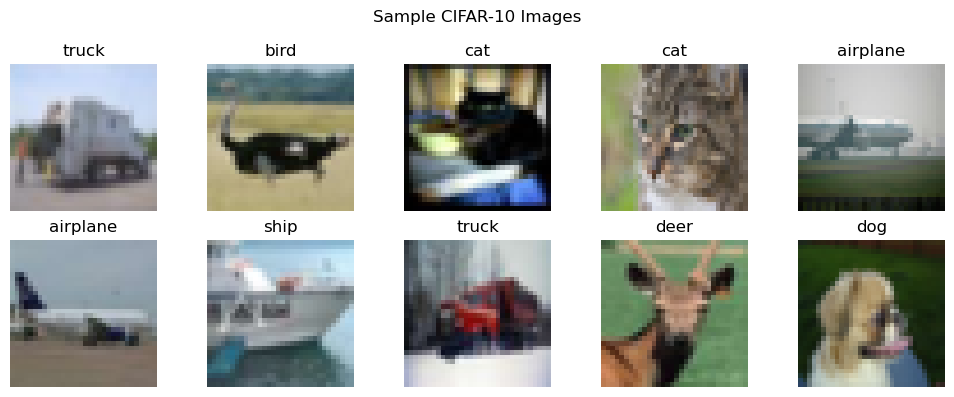

In [4]:
plt.figure(figsize=(10, 4))
for i in range(10):
    idx = np.random.randint(0, x_train.shape[0])
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx])
    plt.title(class_names[np.argmax(y_train[idx])])
    plt.axis('off')
plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

### Defining NN model through Keras Functional API



Earlier we had defined our model through `Keras Sequential` method as follows:

    model = Sequential([
        Input(shape=(32, 32, 3)),

        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),

        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(10, activation='softmax')
    ])

Next, we will define this same model through `Keras Functional API` in next cell

In [5]:
inputs = Input(shape=(32, 32, 3))

x = Conv2D(32, (3, 3), activation='relu', name='conv1')(inputs)
x = MaxPooling2D((2, 2), name='pool1')(x)

x = Conv2D(64, (3, 3), activation='relu', name='conv2')(x)
x = MaxPooling2D((2, 2), name='pool2')(x)

x = Conv2D(128, (3, 3), activation='relu', name='conv3')(x)
x = MaxPooling2D((2, 2), name='pool3')(x)

x = Flatten(name='flatten')(x)
x = Dense(128, activation='relu', name='dense1')(x)

outputs = Dense(10, activation='softmax', name='output')(x)

model = Model(inputs, outputs)

In [6]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 32, 32, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3 (Conv2D)                       │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool3 (MaxPooling2D)                 │ (None, 2, 2, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense1 (Dense)                       │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 160,202 (625.79 KB)

 Trainable params: 160,202 (625.79 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.3230 - loss: 1.8340 - val_accuracy: 0.5093 - val_loss: 1.3631
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.5487 - loss: 1.2643 - val_accuracy: 0.5916 - val_loss: 1.1559
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.6191 - loss: 1.0737 - val_accuracy: 0.6421 - val_loss: 1.0324
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.6691 - loss: 0.9443 - val_accuracy: 0.6544 - val_loss: 0.9980
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 39s 62ms/step - accuracy: 0.6963 - loss: 0.8607 - val_accuracy: 0.6756 - val_loss: 0.9344
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 70ms/step - accuracy: 0.7281 - loss: 0.7821 - val_accuracy: 0.6766 - val_loss: 0.9264
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 76s 61ms/step - accuracy: 0.7510 - loss: 0.7202 - val_accuracy: 0.7011 - val_loss: 0.8807
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 54ms/step - accuracy: 0.7683 - loss: 0.6644 - 

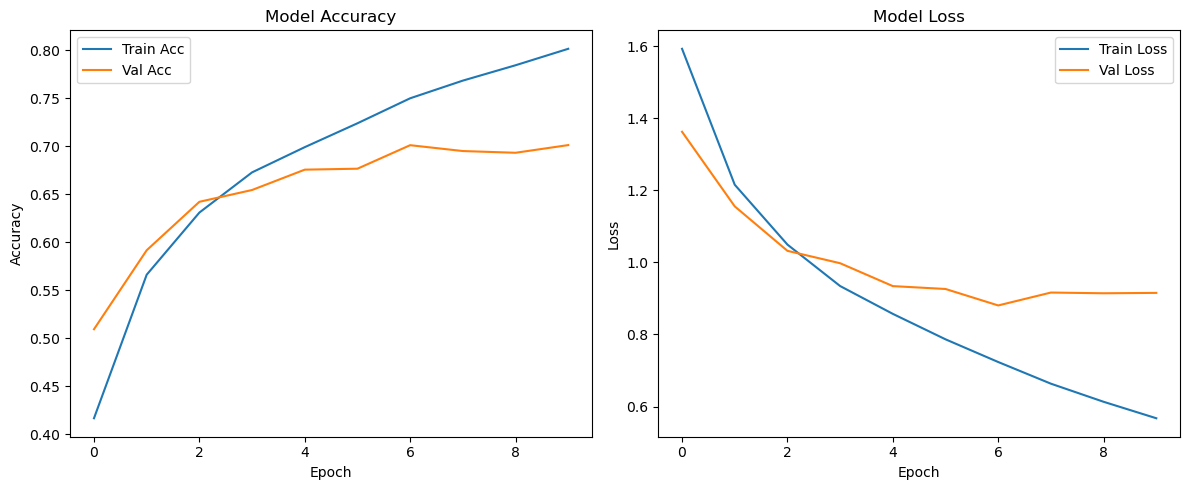

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
# Evaluate
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

# Predict
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

Test Accuracy: 0.6877
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


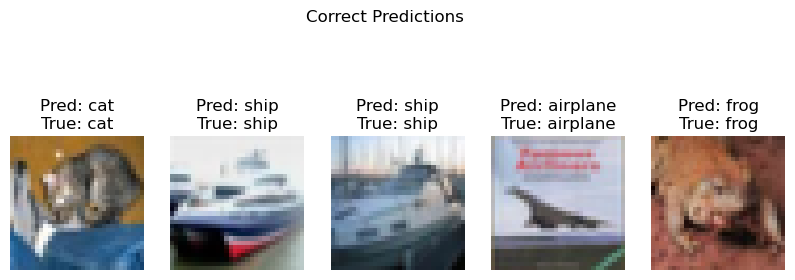

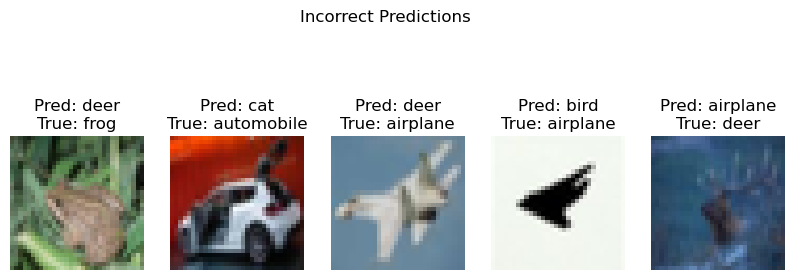

In [11]:
# Correct and incorrect predictions
correct = np.where(y_pred == y_true)[0]
incorrect = np.where(y_pred != y_true)[0]

# Correct
plt.figure(figsize=(10, 4))
for i, idx in enumerate(correct[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"Pred: {class_names[y_pred[idx]]}\nTrue: {class_names[y_true[idx]]}")
    plt.axis("off")
plt.suptitle("Correct Predictions")
plt.show()

# Incorrect
plt.figure(figsize=(10, 4))
for i, idx in enumerate(incorrect[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.title(f"Pred: {class_names[y_pred[idx]]}\nTrue: {class_names[y_true[idx]]}")
    plt.axis("off")
plt.suptitle("Incorrect Predictions")
plt.show()

## Feature Visualization

In [12]:
# Build activation model for intermediate layer outputs
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name or 'pool' in layer.name]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

In [13]:
# Predict activations on 1 sample
sample_img = x_test[0].reshape(1, 32, 32, 3)
activations = activation_model.predict(sample_img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step


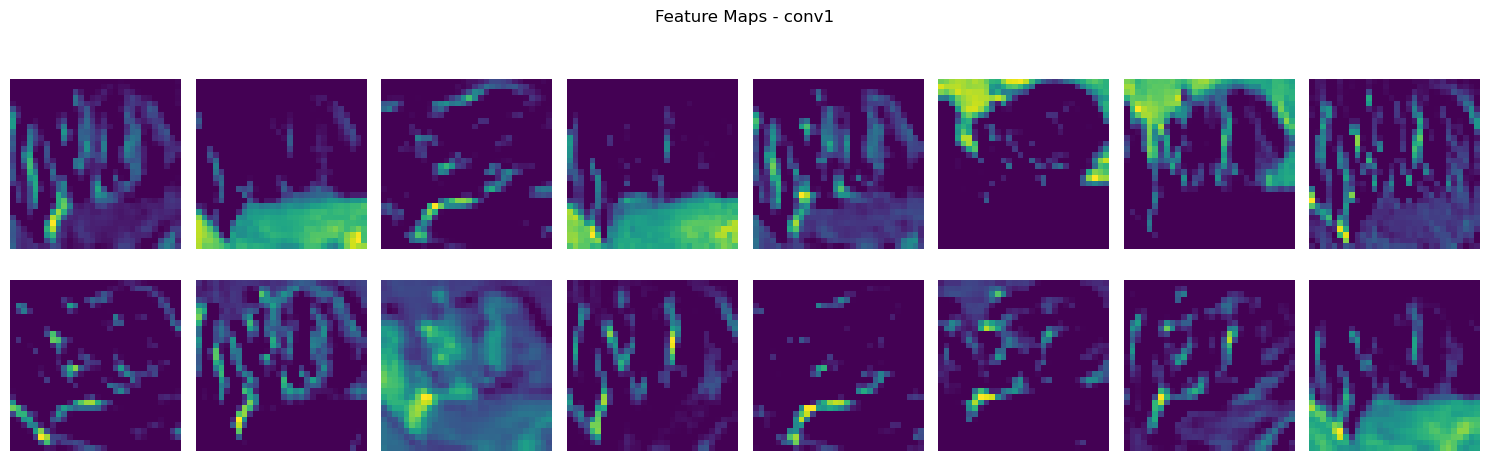

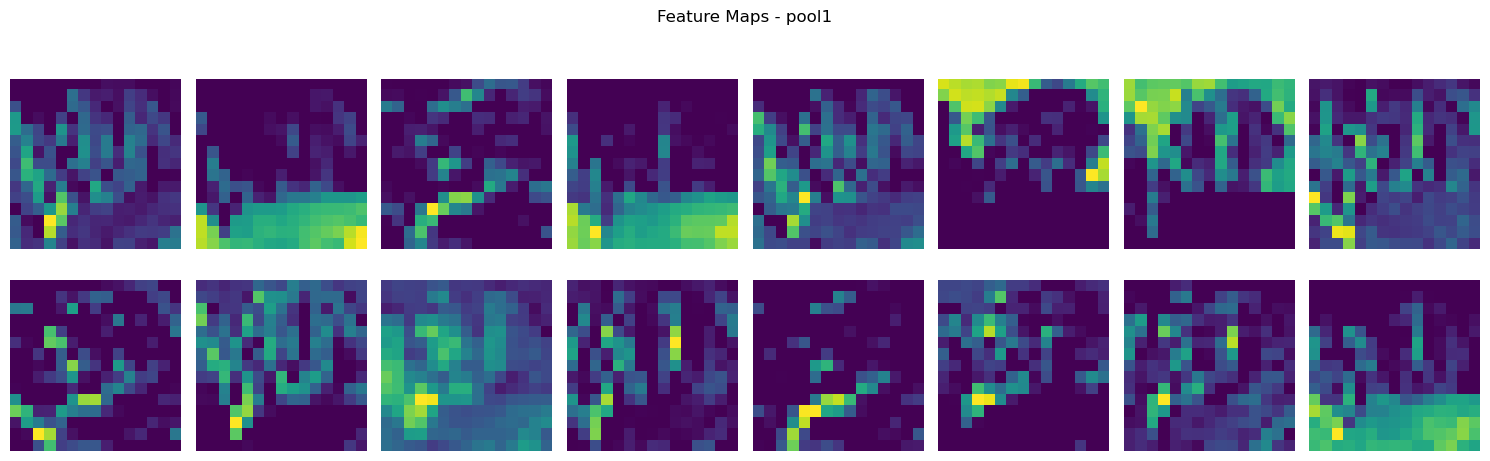

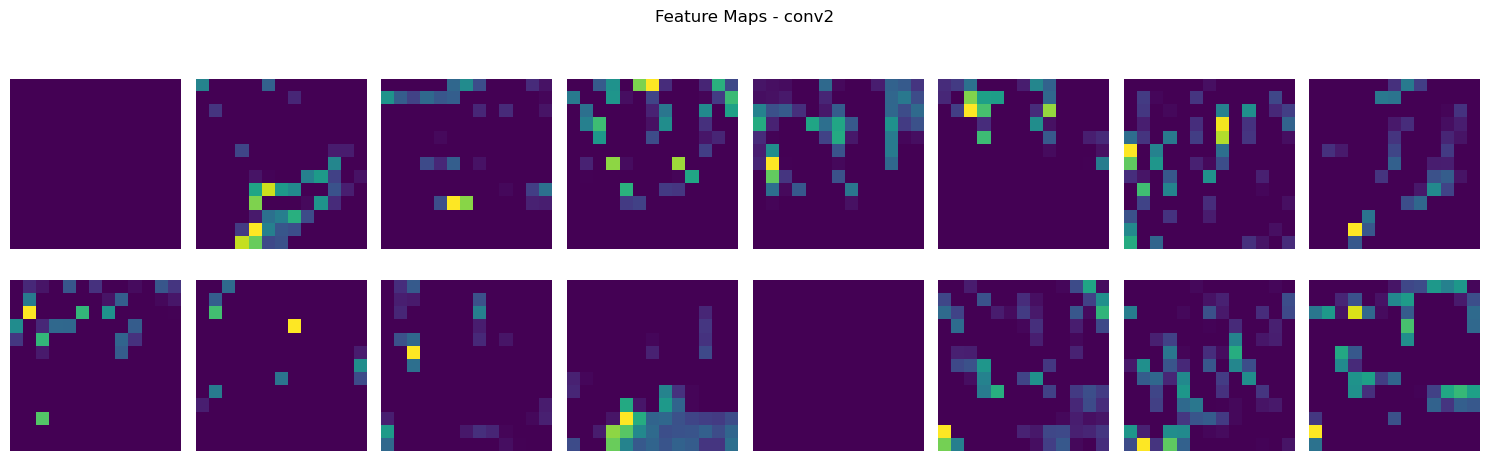

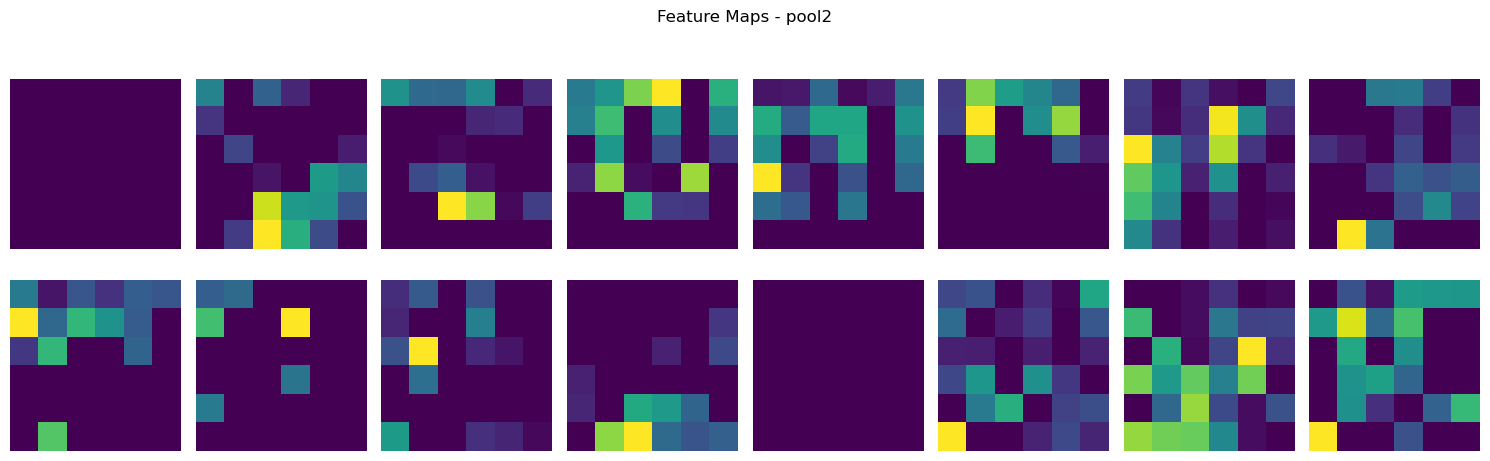

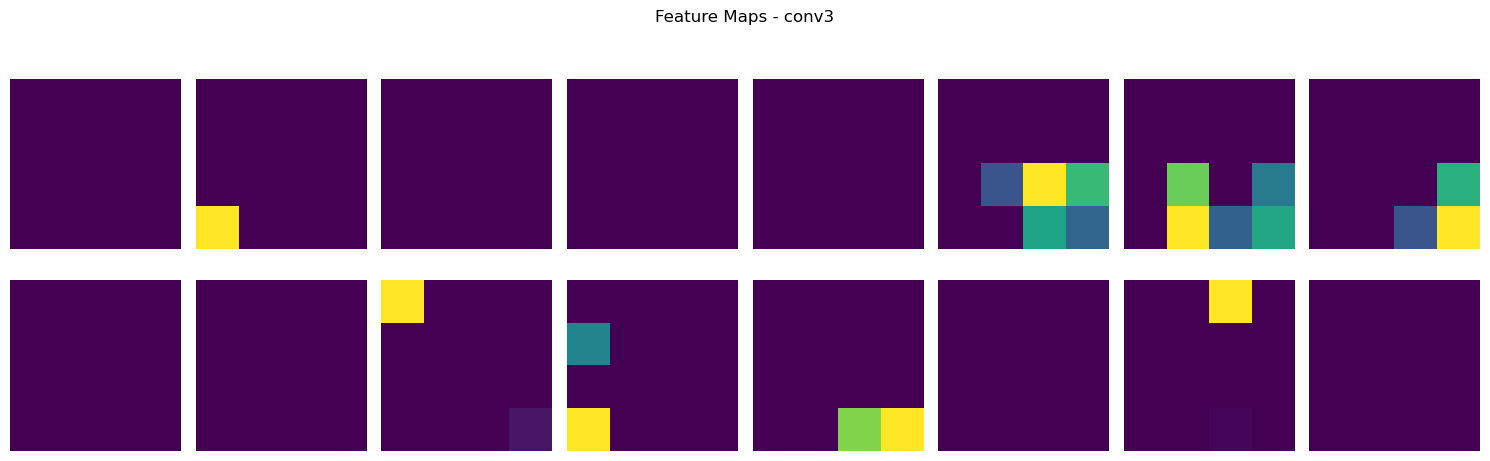

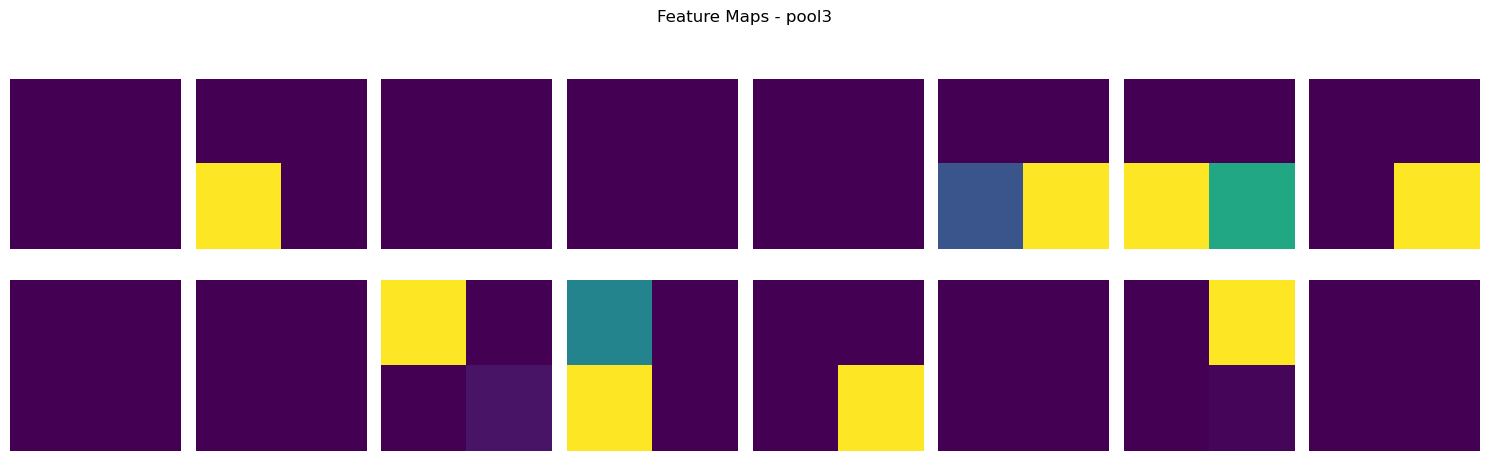

In [14]:
# Visualize feature maps
for layer_activation, layer in zip(activations, activation_model.layers[1:]):
    num_features = layer_activation.shape[-1]
    size = layer_activation.shape[1]

    plt.figure(figsize=(15, 5))
    for i in range(min(16, num_features)):  # Show up to 16 filters
        plt.subplot(2, 8, i + 1)
        plt.imshow(layer_activation[0, :, :, i], cmap='viridis')
        plt.axis('off')
    plt.suptitle(f"Feature Maps - {layer.name}")
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


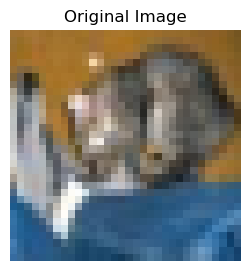

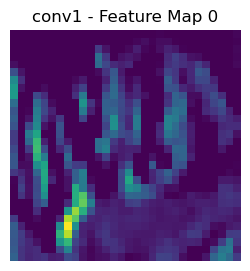

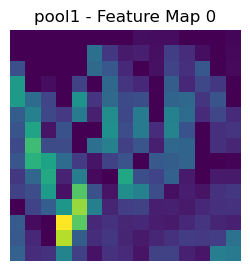

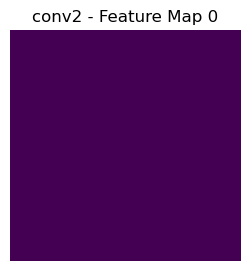

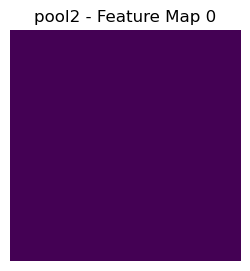

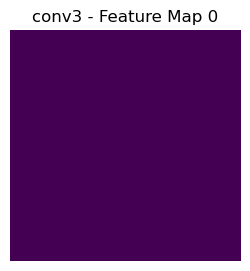

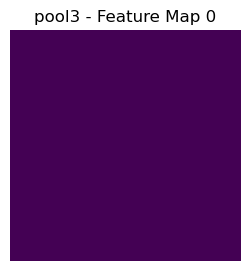

In [15]:
# Display intermediate activations
sample_img = x_test[0].reshape(1, 32, 32, 3)
activations = activation_model.predict(sample_img)

# Plot original image
plt.figure(figsize=(3, 3))
plt.imshow(x_test[0])
plt.title("Original Image")
plt.axis('off')
plt.show()

# Plot 1 feature map from each conv/pool layer
for act, layer in zip(activations, activation_model.layers[1:]):
    feature_map = act[0, :, :, 0]  # Just the first channel

    plt.figure(figsize=(3, 3))
    plt.imshow(feature_map, cmap='viridis')
    plt.title(f"{layer.name} - Feature Map 0")
    plt.axis('off')
    plt.show()

# Rock-Paper-Scissors Image Classification using CNN



This tutorial builds a complete Convolutional Neural Network pipeline on the Rock-Paper-Scissors dataset using TensorFlow/Keras.

We'll cover:
- Data loading and preprocessing
- CNN architecture and training
- Evaluation and visualization
- Understanding intermediate feature maps

**Dataset**: Public dataset from TensorFlow Datasets (TFDS)
**Classes**: `rock`, `paper`, `scissors`


In [16]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

## Dataset Overview

The Rock-Paper-Scissors dataset consists of 2,892 labeled images of hand gestures in three classes:
- Rock
- Paper
- Scissors

Images vary in background, lighting, and hand orientation. This is perfect for teaching CNN concepts in a real-world scenario.

In [ ]:
# Load dataset with supervised labels
(ds_train_full, ds_test), ds_info = tfds.load(
    'rock_paper_scissors',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

In [ ]:
# Reserve validation split from training
val_size = int(0.2 * ds_info.splits['train'].num_examples)
ds_train = ds_train_full.skip(val_size)
ds_val = ds_train_full.take(val_size)

class_names = ds_info.features['label'].names
print("Classes:", class_names)

Classes: ['rock', 'paper', 'scissors']


In [ ]:
IMG_SIZE = 150
BATCH_SIZE = 32
NUM_CLASSES = 3

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_aug = ds_train.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_data = ds_val.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_data = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

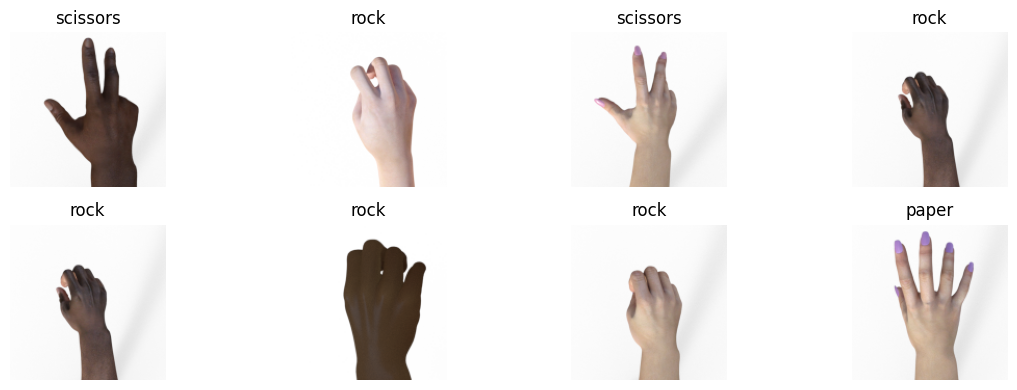

In [ ]:
for images, labels in train_aug.take(1):
    plt.figure(figsize=(12, 4))
    for i in range(8):
        plt.subplot(2, 4, i+1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[tf.argmax(labels[i]).numpy()])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## CNN Architecture

We build a manual CNN using Conv2D and MaxPooling2D layers to extract spatial features.

Layers:
- Conv2D → ReLU → MaxPool
- Conv2D → ReLU → MaxPool
- Dense → Dropout → Softmax

The model is trained using categorical crossentropy for multiclass classification.

In [ ]:
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(32, (3,3), activation='relu', name='conv1')(inputs)
x = MaxPooling2D((2,2), name='pool1')(x)
x = Conv2D(64, (3,3), activation='relu', name='conv2')(x)
x = MaxPooling2D((2,2), name='pool2')(x)
x = Conv2D(128, (3,3), activation='relu', name='conv3')(x)
x = MaxPooling2D((2,2), name='pool3')(x)

x = Flatten(name='flatten')(x)
x = Dense(128, activation='relu', name='dense1')(x)
x = Dropout(0.5)(x)
outputs = Dense(NUM_CLASSES, activation='softmax', name='output')(x)

In [ ]:
model = Model(inputs, outputs)

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,739 (18.42 MB)

 Trainable params: 4,828,739 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_aug,
    epochs=15,
    validation_data=val_data,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=1
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9985 - loss: 0.0064 - val_accuracy: 0.9960 - val_loss: 0.0167
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9941 - loss: 0.0178 - val_accuracy: 0.9980 - val_loss: 0.0032
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9981 - loss: 0.0037 - val_accuracy: 0.9960 - val_loss: 0.0046
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9993 - loss: 0.0040 - val_accuracy: 0.9960 - val_loss: 0.0074
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9997 - loss: 0.0024 - val_accuracy: 0.9980 - val_loss: 0.0040


Test Accuracy: 0.8790


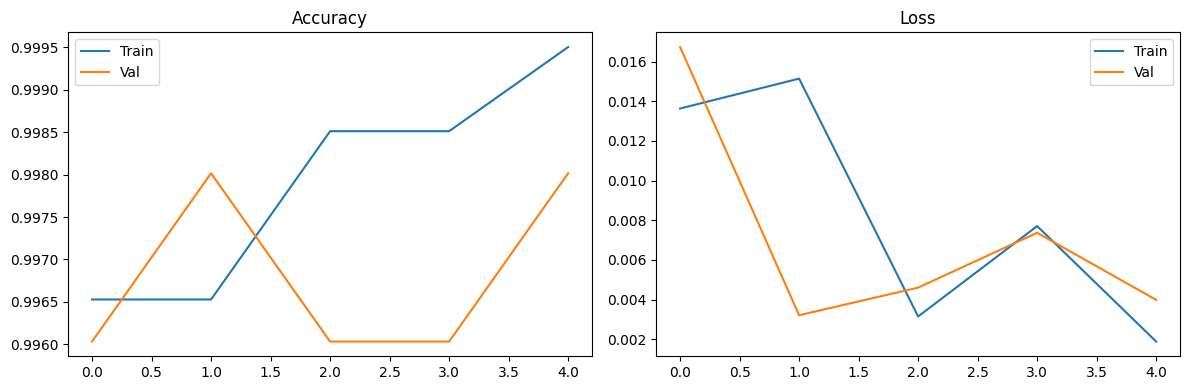

In [ ]:
# Evaluate
loss, acc = model.evaluate(test_data, verbose=0)
print(f"Test Accuracy: {acc:.4f}")

# Plot
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 725ms/step


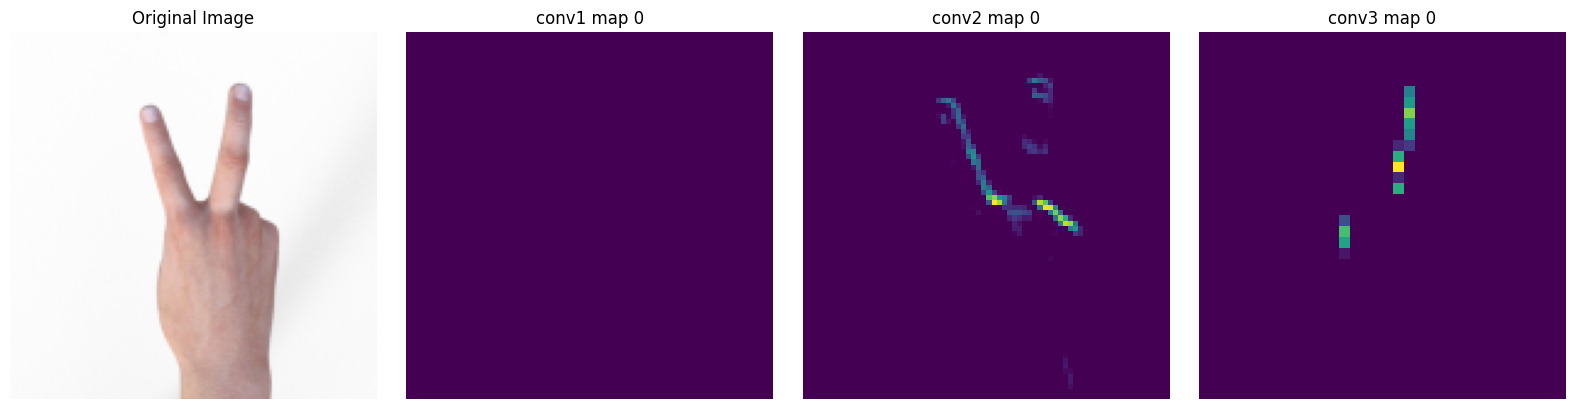

In [ ]:
# Pick a test image
for img_batch, _ in test_data.take(1):
    img = img_batch[0].numpy()
    break

# Create intermediate model for 3 conv layers
intermediate_model = Model(inputs=model.input, outputs=[
    model.get_layer('conv1').output,
    model.get_layer('conv2').output,
    model.get_layer('conv3').output
])

# Predict feature maps
feature_maps = intermediate_model.predict(img.reshape(1, IMG_SIZE, IMG_SIZE, 3))

# Plot original + 3 feature maps (1 from each conv layer) in a single horizontal row
plt.figure(figsize=(16, 4))

# Plot original
plt.subplot(1, 4, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis('off')

# Plot feature map 0 from each conv layer
for i, fmap in enumerate(feature_maps):
    plt.subplot(1, 4, i + 2)
    plt.imshow(fmap[0, :, :, 0], cmap='viridis')
    plt.title(f"conv{i+1} map 0")
    plt.axis('off')

plt.tight_layout()
plt.show()
